In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

import finufft

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals

In [2]:
L = 85

f = utils.generate_centered_gaussian(L, d=2, sigma=2)
f = transforms.translate_2d(f, 0, 5)

g = utils.rotate_image(transforms.translate_2d(f, 0, 15), 180)

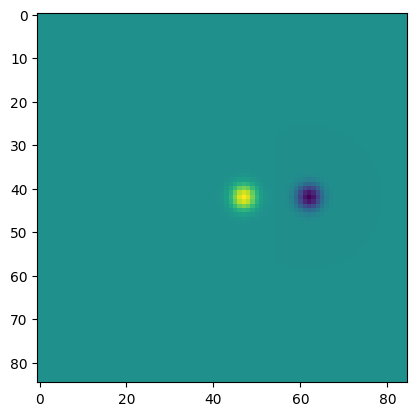

In [3]:
plt.imshow(f - utils.rotate_image(g, 180))

In [4]:
omega = np.linspace(0, 360, L, endpoint=False)

f = signals.Signal(f, d=2, normalize=True).preprocess_signals()
g = signals.Signal(g, d=2, normalize=True).preprocess_signals()

t = time.time()
U = transforms.Transform(f, d=2, apply_ramp=False).inverse_cdf_transform()[0]
V = transforms.Transform(g, d=2, apply_ramp=False).inverse_cdf_transform()[0]
d_sw = distances.fast_rotational_distance_2d(U, V)
print(time.time() - t)

t = time.time()
Up, Un = transforms.Transform(f, d=2, apply_ramp=True).signed_inverse_cdf_transform()
Vp, Vn = transforms.Transform(g, d=2, apply_ramp=True).signed_inverse_cdf_transform()
d_rfsw = distances.fast_signed_rotational_distances_2d(Up[0], Vp[0], Un[0], Vn[0])
print(time.time() - t)

d_l2 = distances.rotational_euclidean_distance_2d(f[0], g[0], omega)

0.009495973587036133
0.007231235504150391


In [5]:
d_l2_norm = d_l2 / np.amax(d_l2)
d_sw_norm = d_sw / np.amax(d_sw)
d_rfsw_norm = d_rfsw / np.amax(d_rfsw)

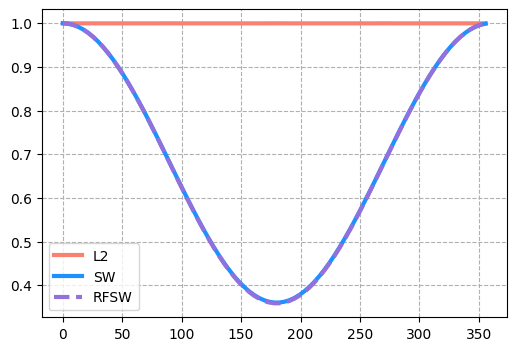

In [6]:
plt.figure(figsize=(6,4))
plt.plot(omega, d_l2_norm, linewidth=3, color='salmon', label='L2')
plt.plot(omega, d_sw_norm, linewidth=3, color='dodgerblue', label='SW')
plt.plot(omega, d_rfsw_norm, linewidth=3, linestyle='--', color='mediumpurple', label='RFSW')
plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

In [18]:
print('RFSW: ', omega[np.argmin(d_rfsw_norm)])
print('SW: ', omega[np.argmin(d_sw_norm)])
print('L2: ', omega[np.argmin(d_l2_norm)])

RFSW:  182.11764705882354
SW:  177.88235294117646
L2:  12.705882352941178


In [8]:


### Test / add the signed , normalizations here



In [9]:
f = utils.generate_3d_triangle_gaussian_shape(L=65, sigma=2, rescale=False).sum(axis=0)
f = signals.Signal(f, d=2, normalize=True).preprocess_signals()

U = transforms.Transform(f, d=2, apply_ramp=True).radon_transform()[0]
Up, Un = transforms.hahn_decomposition(U)

np.float64(1.0)

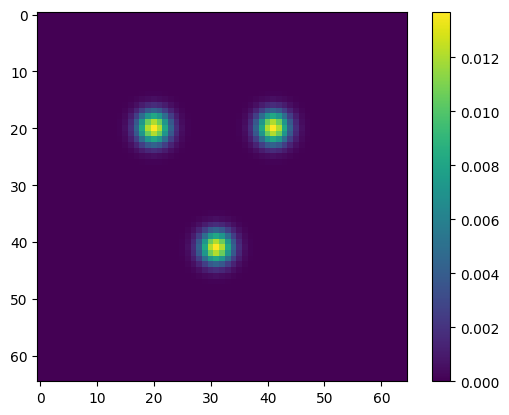

In [10]:
plt.imshow(f[0])
plt.colorbar()
np.sum(f)

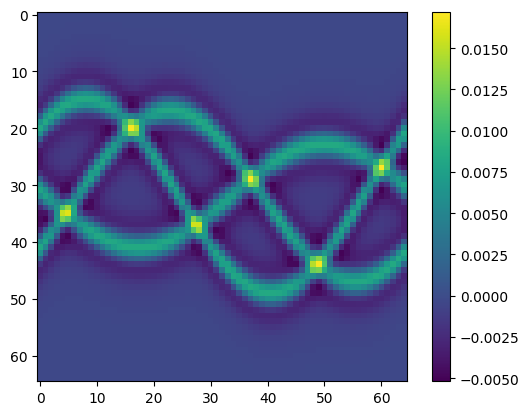

In [11]:
plt.imshow(U)
plt.colorbar()
plt.show()
# plots.two_imshow(Up, abs(Un))

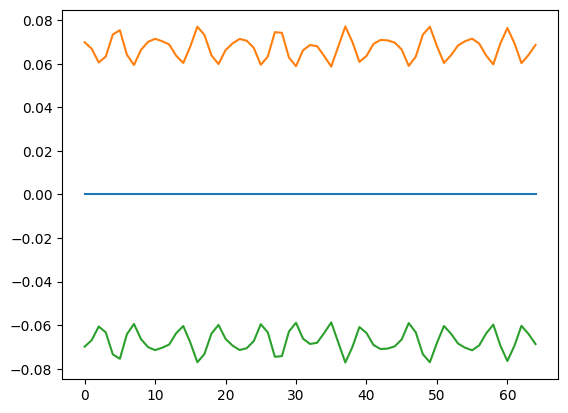

In [12]:
plt.plot(np.sum(U, axis=0))
plt.plot(np.sum(Up, axis=0))
plt.plot(np.sum(Un, axis=0))
# plt.ylim(-0.1, 1.1)
plt.show()

In [13]:
f = utils.generate_3d_triangle_gaussian_shape(L=65, sigma=2, rescale=True).sum(axis=0)
f = signals.Signal(f, d=2, normalize=False).preprocess_signals()

z_cdf = transforms.Transform(f, d=2, apply_ramp=False).cdf_transform(normalize=True)
z_p_cdf, z_n_cdf = transforms.Transform(f, d=2, apply_ramp=True).signed_cdf_transform(normalize=True)

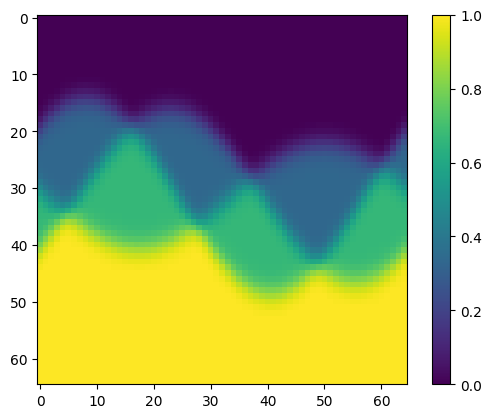

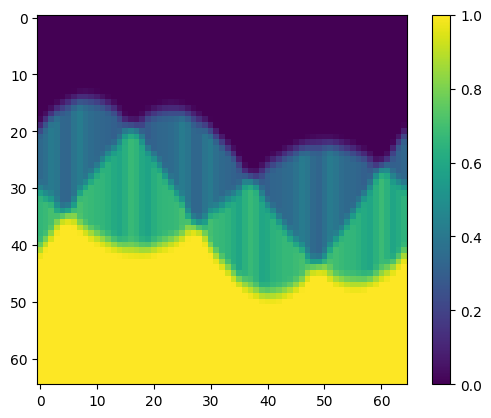

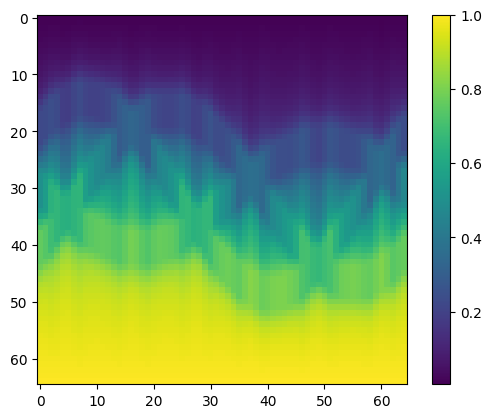

In [14]:
plots.image_plot(z_cdf[0])
plots.image_plot(z_p_cdf[0])
plots.image_plot(z_n_cdf[0])

In [15]:
f = utils.generate_3d_triangle_gaussian_shape(L=128, sigma=5, rescale=True).sum(axis=0)
f = signals.Signal(f, d=2, normalize=False).preprocess_signals()

t = time.time()
z_icdf = transforms.Transform(f, d=2, apply_ramp=False).inverse_cdf_transform(normalize=True)
print(time.time() - t)
t = time.time()
z_p_icdf, z_n_icdf = transforms.Transform(f, d=2, apply_ramp=True).signed_inverse_cdf_transform(normalize=True)
print(time.time() - t)

0.005892753601074219
0.005820512771606445


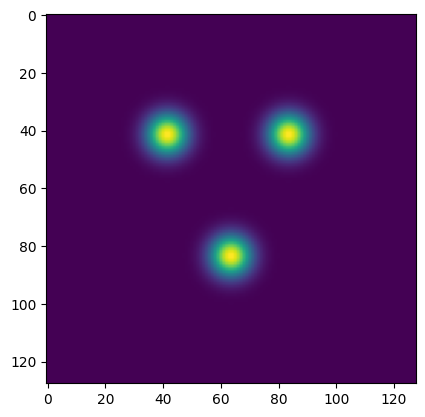

In [16]:
plt.imshow(f[0])

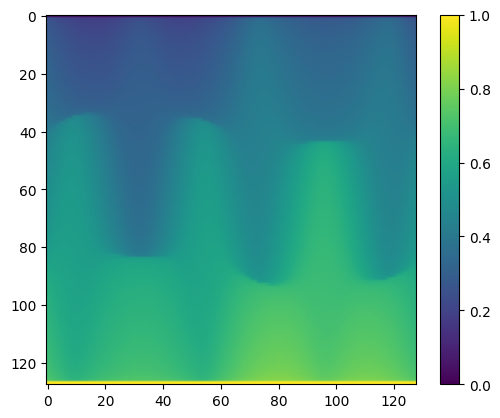

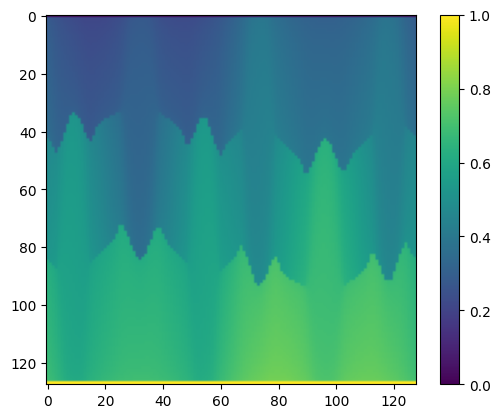

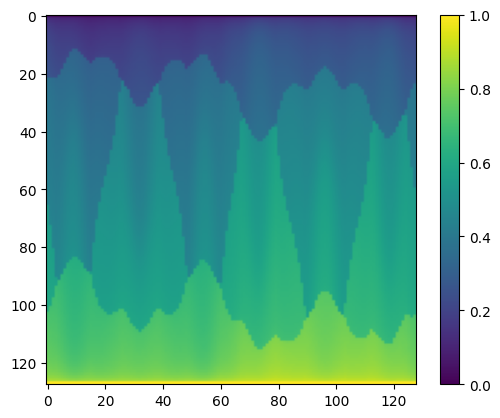

In [17]:
plots.image_plot(z_icdf[0])
plots.image_plot(z_p_icdf[0])
plots.image_plot(z_n_icdf[0])